## Imports

In [ ]:
from pathlib import Path

PROJECT_DIR = Path.cwd().resolve()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

SRC_DIR = PROJECT_DIR / "src" / "transformer"
LOCAL_DIR = SRC_DIR

import sys
sys.path.insert(0, str(PROJECT_DIR))

import json
import hashlib
from datetime import datetime, date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import precision_recall_curve, average_precision_score
from IPython.display import display

from src.transformer import build_history_windows as windows
from src.transformer import transformer_training as training

sys.path.insert(0, str(PROJECT_DIR / "notebooks"))
import safeflow_features as sf

## Settings

In [ ]:
MODEL_NAME = "transformer_shared_plus_agreed_features"
QUICK_RUN = False                 # True: 2025 Q2 only; False: all six shared folds
TRAIN_SAMPLE = 2_000_000           # None for all eligible training endpoints
SAMPLE_SEED = 0                   # Same sampling convention as the shared notebook
MODEL_SEED = 42
LOOKBACK = 24                     # Up to 24 contiguous five-minute observations
EPOCHS = 10                       # Fixed; no best-quarter-validation checkpoint selection
BATCH_SIZE = 256
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 0.01
CPU_THREADS = 4
KEEP_FEATURE_CACHE = False        # Temporary on-disk feature matrix removed after each fold
MODEL_PARAMETERS = dict(d_model=64, nhead=4, num_layers=2, d_ff=128, dropout=0.1)

# Dir
DATA_DIR = PROJECT_DIR / "Data"
METADATA_FILE = DATA_DIR / sf.META_FILE_NAME

# PyTorch device settings
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(CPU_THREADS)

RUN_NAME = f"{MODEL_NAME}_{datetime.now():%Y%m%d_%H%M%S_%f}"
RUN_DIR = LOCAL_DIR / "results" / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=False)

assert RUN_DIR.resolve().is_relative_to(LOCAL_DIR)
print("Device:", DEVICE)
print("Outputs:", RUN_DIR)
print("Run mode:", "LAST FOLD ONLY" if QUICK_RUN else "ALL SIX FOLDS")

Device: cpu
Outputs: /home/alexk/projects/erdos_data_science/traffic_project_explore/transformer/results/transformer_shared_plus_agreed_features_20261031_085746_133888
Run mode: ALL SIX FOLDS


## 1. Load data and define the feature list

In [ ]:
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Set DATA_DIR to the existing PeMS data directory: {DATA_DIR}")

# Build the dataset as pandas DF
df = sf.build_dataset(DATA_DIR)

FEATURES = list(sf.SHARED_FEATURES)

# Basic checks
assert not df.duplicated(sf.KEY).any()
assert df["timestamp"].max() < pd.Timestamp(sf.HOLDOUT_START)

history_index = windows.HistoryIndex(df, target_column="y")
folds = list(sf.folds(df, only_last=QUICK_RUN))

print(f"{len(df):,} observations; {df['station'].nunique()} stations")
print(f"{len(FEATURES)} logical features:")
display(pd.DataFrame({"feature": FEATURES}))
print("Validation folds:", [fold.name for fold in folds])

read 100/1094 files (1s)
read 200/1094 files (1s)
read 300/1094 files (2s)
read 500/1094 files (3s)
read 600/1094 files (3s)
read 800/1094 files (4s)
read 900/1094 files (5s)
624 weekdays used out of 1094 files (182 holdout files skipped, never read)
4,819,328 rows | 46 stations | scored rows 54% | onsets 13,573
4,819,328 observations; 46 stations
29 logical features:


,feature
0,speed_anomaly
1,occ_anomaly
2,typical_congestion_30
3,speed_delta_2
4,flow
5,down_minus_here
6,up_minus_here
7,tod_sin
8,tod_cos
9,dow


Validation folds: ['2024-01 to 2024-03', '2024-04 to 2024-06', '2024-07 to 2024-09', '2024-10 to 2024-12', '2025-01 to 2025-03', '2025-04 to 2025-06']


## 2. Train and validate

For new runs, rerun the settings cell.

In [ ]:
fold_results, prediction_parts, learning_curves = [], [], []

for fold in folds:
    print(f"\n{fold.name}", flush=True)
    sf.add_typical_features(df, fold.train)

    train_rows = np.flatnonzero((fold.train & df["y_known"]).to_numpy())

    if TRAIN_SAMPLE is not None and len(train_rows) > TRAIN_SAMPLE:
        train_rows = pd.Series(train_rows).sample(TRAIN_SAMPLE, random_state=SAMPLE_SEED).to_numpy()
    
    train_rows = np.sort(train_rows)# fit_fold creates a NEW model, optimizer and training-only preprocessing.
    validation_rows = np.flatnonzero(fold.val.to_numpy())

    assert df.loc[fold.train, "window_end"].max() < (
        df.iloc[validation_rows]["timestamp"].min().normalize() - pd.Timedelta(days=sf.GAP_DAYS)
    )

    # Create *new* model + optimizer + preprocessing (training-only) using fit_fold
    fold_dir = RUN_DIR / fold.name[:7]
    result = training.fit_fold(
        df, history_index, FEATURES, train_rows, validation_rows, fold_dir,
        lookback=LOOKBACK, epochs=EPOCHS, batch_size=BATCH_SIZE, learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY, seed=MODEL_SEED, device=DEVICE, model_parameters=MODEL_PARAMETERS, keep_cache=KEEP_FEATURE_CACHE)
    
    val = df.iloc[validation_rows]
    probability = result["probability"]

    assert np.array_equal(result["positions"], validation_rows)
    assert len(probability) == len(val) and np.isfinite(probability).all()

    # Define metrics
    metrics = sf.score(val, probability)
    fold_results.append({"fold": fold.name, **metrics, "train_rows": len(train_rows), "tensor_channels": result["n_tensor_channels"]})

    kept = val[sf.KEY + ["date", "y", "y_known", "congested_now", "real", "onset"]].copy()
    kept["fold"] = fold.name
    kept["probability"] = probability
    kept.to_parquet(fold_dir / "validation_predictions.parquet", index=False)

    prediction_parts.append(kept)

    learning_curves.append(result["history"].assign(fold=fold.name))

    pd.DataFrame(fold_results).to_csv(RUN_DIR / "fold_results.csv", index=False)

    print(f"AP onsets {metrics['AP, onsets']:.4f} | Brier {metrics['Brier']:.4f} | "
          f"caught >=15 min {metrics['caught ≥15 min']:.1%} | "
          f"false alarms/day {metrics['false alarms / day']:.1f}")

fold_results = pd.DataFrame(fold_results).set_index("fold")
predictions = pd.concat(prediction_parts, ignore_index=True).sort_values(sf.KEY).reset_index(drop=True)
learning_curves = pd.concat(learning_curves, ignore_index=True)


2024-01 to 2024-03
  epoch 01/10: BCE=0.0840, 161.2s
  epoch 02/10: BCE=0.0786, 160.1s
  epoch 03/10: BCE=0.0766, 179.8s
  epoch 04/10: BCE=0.0750, 172.0s
  epoch 05/10: BCE=0.0737, 178.6s
  epoch 06/10: BCE=0.0725, 166.5s
  epoch 07/10: BCE=0.0713, 162.0s
  epoch 08/10: BCE=0.0701, 157.1s
  epoch 09/10: BCE=0.0693, 151.1s
  epoch 10/10: BCE=0.0682, 157.3s
AP onsets 0.7317 | Brier 0.0234 | caught >=15 min 69.2% | false alarms/day 35.0

2024-04 to 2024-06
  epoch 01/10: BCE=0.0830, 213.1s
  epoch 02/10: BCE=0.0780, 206.3s
  epoch 03/10: BCE=0.0761, 217.2s
  epoch 04/10: BCE=0.0746, 225.3s
  epoch 05/10: BCE=0.0733, 220.4s
  epoch 06/10: BCE=0.0723, 214.9s
  epoch 07/10: BCE=0.0714, 217.9s
  epoch 08/10: BCE=0.0703, 216.2s
  epoch 09/10: BCE=0.0696, 225.7s
  epoch 10/10: BCE=0.0687, 222.2s
AP onsets 0.7709 | Brier 0.0207 | caught >=15 min 67.9% | false alarms/day 31.0

2024-07 to 2024-09
  epoch 01/10: BCE=0.0806, 291.6s
  epoch 02/10: BCE=0.0760, 259.9s
  epoch 03/10: BCE=0.0743, 262.5

## 3. Results per fold + learning curves + primary precision–recall curve

,"AP, onsets","AP, all",Brier,caught ≥15 min,false alarms / day,wrong-alert hours / day,alerts right,median lead (min),onsets
fold,,,,,,,,,
2024-01 to 2024-03,0.7317,0.9601,0.0234,0.6917,35.0484,7.3683,0.8872,30.0000,1706.0000
2024-04 to 2024-06,0.7709,0.9617,0.0207,0.6793,30.9524,5.4894,0.8974,25.0000,1453.0000
2024-07 to 2024-09,0.7613,0.9613,0.0231,0.6358,26.7344,4.8789,0.9059,25.0000,1491.0000
2024-10 to 2024-12,0.7785,0.9701,0.0231,0.6501,28.3387,4.6680,0.9222,25.0000,1546.0000
2025-01 to 2025-03,0.7592,0.9681,0.0224,0.6835,31.7705,5.9290,0.9050,25.0000,1561.0000
2025-04 to 2025-06,0.7732,0.9687,0.0210,0.6393,29.7460,4.9286,0.9168,25.0000,1536.0000
mean,0.7625,0.9650,0.0223,0.6633,30.4317,5.5437,0.9057,25.8333,1548.8333
std,0.0168,0.0044,0.0011,0.0244,2.8948,1.0067,0.0127,2.0412,86.6612


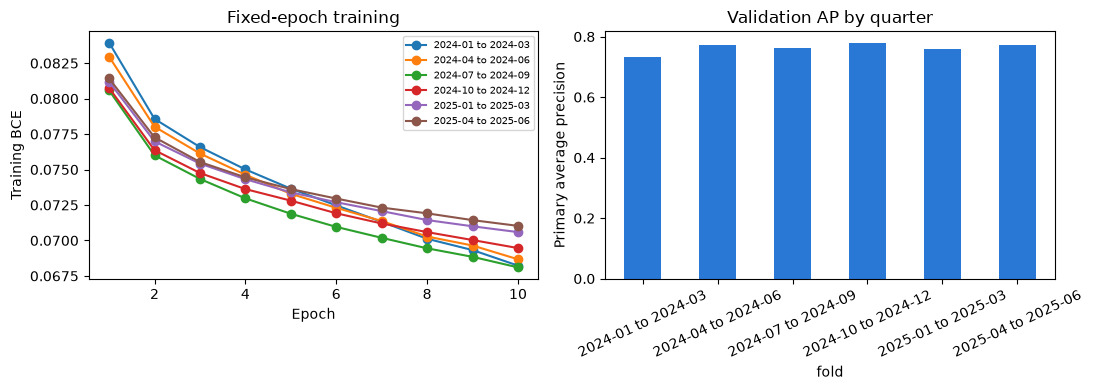

In [ ]:
metric_columns = ["AP, onsets", "AP, all", "Brier", "caught ≥15 min", "false alarms / day", "wrong-alert hours / day", "alerts right", "median lead (min)", "onsets"]

table = fold_results[metric_columns].copy()
table.loc["mean"] = fold_results[metric_columns].mean()
table.loc["std"] = fold_results[metric_columns].std()
display(table.round(4))

# Learning curves: BCE + AP
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for name, part in learning_curves.groupby("fold", sort=False):
    axes[0].plot(part["epoch"], part["train_BCE"], marker="o", label=name)

axes[0].set(xlabel="Epoch", ylabel="Training BCE", title="Fixed-epoch training")
axes[0].legend(fontsize=7)
fold_results["AP, onsets"].plot.bar(ax=axes[1], color="#2a78d6")
axes[1].set(ylabel="Primary average precision", title="Validation AP by quarter")
axes[1].tick_params(axis="x", rotation=25)

fig.tight_layout()
plt.show()

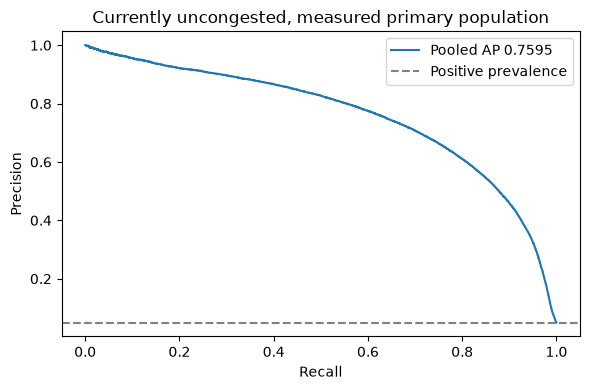

Mean per-fold AP: 0.762460316514651
Pooled AP: 0.7595468463629494


In [ ]:
primary = predictions["y_known"] & predictions["real"] & ~predictions["congested_now"]
primary_rows = predictions.loc[primary]

precision, recall, _ = precision_recall_curve(primary_rows["y"], primary_rows["probability"])

pooled_AP = average_precision_score(primary_rows["y"], primary_rows["probability"])

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(recall, precision, label=f"Pooled AP {pooled_AP:.4f}")
ax.axhline(primary_rows["y"].mean(), color="grey", linestyle="--", label="Positive prevalence")
ax.set(xlabel="Recall", ylabel="Precision", title="Currently uncongested, measured primary population")
ax.legend()

fig.tight_layout()
plt.show()

print("Mean per-fold AP:", fold_results["AP, onsets"].mean())
print("Pooled AP:", pooled_AP)

## 4. Catching jams versus false alarms

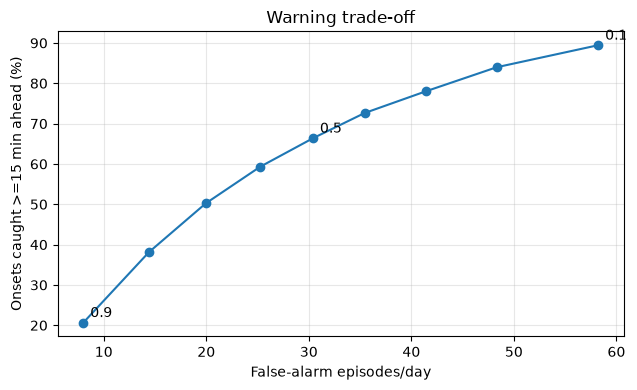

,caught ≥15 min,false alarms / day,wrong-alert hours / day,alerts right,median lead (min),onsets
threshold,,,,,,
0.1,0.894,58.224,18.179,0.759,30.0,9293
0.2,0.840,48.317,12.366,0.820,30.0,9293
0.3,0.780,41.416,9.257,0.857,30.0,9293
0.4,0.726,35.440,7.143,0.884,30.0,9293
0.5,0.664,30.408,5.537,0.906,25.0,9293
0.6,0.593,25.267,4.217,0.925,25.0,9293
0.7,0.502,19.952,3.025,0.943,20.0,9293
0.8,0.381,14.411,1.948,0.961,15.0,9293
0.9,0.207,8.013,0.919,0.979,10.0,9293


In [ ]:
thresholds = np.round(np.arange(0.1, 0.91, 0.1), 2)
tradeoff = pd.DataFrame([
    sf.alert_metrics(predictions, predictions["probability"].to_numpy(), t) for t in thresholds
], index=pd.Index(thresholds, name="threshold"))

fig, ax = plt.subplots(figsize=(6.5, 4))

ax.plot(tradeoff["false alarms / day"], tradeoff["caught ≥15 min"] * 100, marker="o")

for t in (0.1, 0.5, 0.9):
    ax.annotate(str(t), (tradeoff.loc[t, "false alarms / day"], tradeoff.loc[t, "caught ≥15 min"] * 100), xytext=(5, 4), textcoords="offset points")
    
ax.set(xlabel="False-alarm episodes/day", ylabel="Onsets caught >=15 min ahead (%)", title="Warning trade-off")
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()
display(tradeoff.round(3))

## 5. Probability calibration

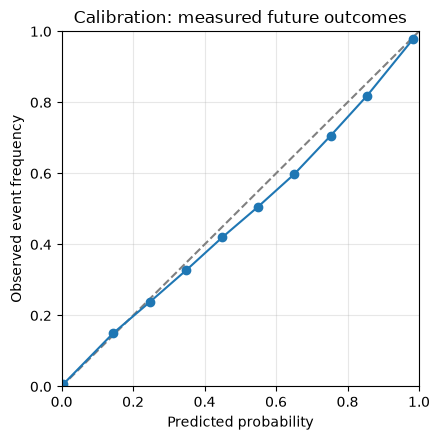

,predicted,actual,rows
probability,,,
"(-0.001, 0.1]",0.004,0.006,1417137
"(0.1, 0.2]",0.144,0.150,30775
"(0.2, 0.3]",0.247,0.238,18363
"(0.3, 0.4]",0.349,0.327,14142
"(0.4, 0.5]",0.449,0.420,12452
"(0.5, 0.6]",0.550,0.506,12036
"(0.6, 0.7]",0.651,0.598,13349
"(0.7, 0.8]",0.753,0.706,16489
"(0.8, 0.9]",0.855,0.819,25584


In [ ]:
scored = predictions.loc[predictions["y_known"]]
bins = pd.cut(scored["probability"], np.linspace(0, 1, 11), include_lowest=True)

calibration = scored.groupby(bins, observed=True).agg(predicted=("probability", "mean"), actual=("y", "mean"), rows=("y", "size"))
calibration = calibration[calibration["rows"] >= 100]

calibration.to_csv(RUN_DIR / "calibration.csv")
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], "--", color="grey")
ax.plot(calibration["predicted"], calibration["actual"], marker="o")
ax.set(xlabel="Predicted probability", ylabel="Observed event frequency", xlim=(0, 1), ylim=(0, 1),
       title="Calibration: measured future outcomes")
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

display(calibration.round(3))

## By-station summary of contributions

Predictions made for stations that don't have eligible outcomes shouldn't count for validated performance. This summarizes the coverage

In [ ]:
coverage = []

for station, part in predictions.groupby("station"):
    eligible = part["y_known"] & part["real"] & ~part["congested_now"]
    coverage.append({"station": station, "predictions": len(part), "known_outcomes": int(part["y_known"].sum()), "primary_rows": int(eligible.sum()), "primary_positives": int(part.loc[eligible, "y"].sum())})

coverage = pd.DataFrame(coverage)

display(coverage)
print("Stations with primary scoring:", coverage["primary_rows"].gt(0).sum(), "/", len(coverage))

,station,predictions,known_outcomes,primary_rows,primary_positives
0,1205045,63000,0,0,0
1,1205071,63000,28244,27100,1952
2,1205088,63000,46171,25634,4509
3,1205135,63000,51741,44199,7483
4,1205152,63000,56478,56065,363
5,1205157,63000,4181,4170,36
6,1205165,63000,60046,58348,2857
7,1205168,63000,20016,15426,1573
8,1205175,63000,59970,42800,4559
9,1205193,63000,2268,1970,282


Stations with primary scoring: 40 / 46


## 6. Save + team comparison

In [ ]:
summary_row = {
    "model": MODEL_NAME,
    "date run": date.today().isoformat(),
    "features": len(FEATURES),
    "AP onsets (mean)": fold_results["AP, onsets"].mean(),
    "AP onsets (std)": fold_results["AP, onsets"].std(),
    "AP onsets (worst fold)": fold_results["AP, onsets"].min(),
    "Brier": fold_results["Brier"].mean(),
    "caught ≥15 min @0.5": fold_results["caught ≥15 min"].mean(),
    "false alarms/day @0.5": fold_results["false alarms / day"].mean(),
    "wrong-alert hours/day @0.5": fold_results["wrong-alert hours / day"].mean(),
}
summary_table = pd.DataFrame([summary_row])

RESULTS = PROJECT_DIR / "notebooks" / "results"

if QUICK_RUN:
    print("Quick run: results not saved")
else:
    fold_results.round(4).to_csv(RESULTS / f"{MODEL_NAME}_folds.csv")

    summary_file = RESULTS / "summary.csv"
    summary = pd.read_csv(summary_file) if summary_file.exists() else pd.DataFrame()

    # If earlier one exists, replace with this model name
    if not summary.empty:
        summary = summary.loc[summary["model"] != MODEL_NAME]

    summary = pd.concat([summary, summary_table], ignore_index=True).sort_values("AP onsets (mean)", ascending=False)

    summary.round(4).to_csv(summary_file, index=False)
    display(summary.set_index("model").round(4))

,model,date run,features,AP onsets (mean),AP onsets (std),AP onsets (worst fold),Brier,caught ≥15 min @0.5,false alarms/day @0.5,wrong-alert hours/day @0.5
0,transformer_shared_plus_agreed_features,2026-10-31,29,0.7625,0.0168,0.7317,0.0223,0.6633,30.4317,5.5437


Saved inside: /home/alexk/projects/erdos_data_science/traffic_project_explore/transformer/results/transformer_shared_plus_agreed_features_20261031_085746_133888
Holdout remains unopened. Review the local marked feature copy with the team before any final evaluation.
